# Model Evaluation Notebook v2 (Standalone)

**Self-contained evaluation framework with all improvements in one notebook.**

## What's New in v2:

### Security
- ✅ No hardcoded HuggingFace tokens (uses .env file)
- ✅ Token in environment variable only

### Configuration
- ✅ All settings centralized in Section 1
- ✅ No scattered magic numbers
- ✅ Easy parameter tuning

### New Diagnostics
- ✅ Confusion matrix visualization (TP/FP/TN/FN)
- ✅ Error analysis (detailed FP/FN breakdown)
- ✅ Inference speed benchmarking
- ⚠️ Adversarial diagnostic (needs category data)

### Code Quality
- ✅ All utility functions included
- ✅ Input validation throughout
- ✅ Reproducibility guaranteed (all seeds set)
- ✅ Better error handling
- ✅ Environment metadata tracking

## How to Use:

1. Create `.env` file: `echo "HUGGINGFACE_TOKEN=hf_xxxxx" > .env`
2. Open this notebook
3. Run All Cells

**Everything is self-contained - no external modules required!**


## 1. Configuration (All Settings Here)

In [ ]:
"""Configuration - Modify all settings here."""

from pathlib import Path

# ============================================================================
# PATHS
# ============================================================================

PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / 'data_new'
MODELS_DIR = PROJECT_ROOT / 'models'
RESULTS_DIR = MODELS_DIR / 'results'

# Data files
INCIDENT_DATA_FILE = 'SNow_incident_ticket_data.csv'
TEST_PAIRS_FILE = 'fixed_test_pairs.json'

# ============================================================================
# MODELS
# ============================================================================

# Baseline model
BASELINE_MODEL = 'sentence-transformers/all-mpnet-base-v2'

# Fine-tuned models to evaluate
FINETUNED_MODELS = [
    #'v6_refactored_finetuned/v6_refactored_finetuned_20251204_1424',
    #'real_servicenow_finetuned_mpnet/real_servicenow_v2_20251210_1939',
    #'real_servicenow_finetuned_mpnet_lora/real_servicenow_v2_20251226_1637',
    'real_servicenow_finetuned_mpnet_lora/real_servicenow_v2_20251227_0214',  # Latest with MatryoshkaLoss + MNRL
    'real_servicenow_finetuned_mpnet_lora/real_servicenow_v2_20251228_0418',  # With expanded data
    'real_servicenow_finetuned_mpnet_lora/phase3_only_20260101_1238',  # Phase 3-only (no curriculum) - Spearman 0.4955
    'real_servicenow_finetuned_mpnet_lora/real_servicenow_v2_20260104_2321',  # V4 Cosine Loss - Production Ready (Spearman 0.498)
]

# Additional baseline models
ADDITIONAL_BASELINES = [
    {'name': 'all-MiniLM-L6-v2', 'model_id': 'sentence-transformers/all-MiniLM-L6-v2',
     'trust_remote_code': False, 'batch_size': 32},

    {'name': 'EmbeddingGemma-300M', 'model_id': 'google/embeddinggemma-300m',
     'trust_remote_code': True, 'batch_size': 32},

    # Qwen3-Embedding-8B Matryoshka dimension sweep
    #{'name': 'Qwen3-8B-768', 'model_id': 'Qwen/Qwen3-Embedding-8B',
    # 'trust_remote_code': True, 'batch_size': 4, 'truncate_dim': 768},

    #{'name': 'Qwen3-8B-1024', 'model_id': 'Qwen/Qwen3-Embedding-8B',
    # 'trust_remote_code': True, 'batch_size': 4, 'truncate_dim': 1024},

    #{'name': 'Qwen3-8B-4096', 'model_id': 'Qwen/Qwen3-Embedding-8B',
    # 'trust_remote_code': True, 'batch_size': 4, 'truncate_dim': 4096},
]

# ============================================================================
# EVALUATION SETTINGS
# ============================================================================

RANDOM_SEED = 42
NUM_THRESHOLDS = 100  # For optimal F1 search
MIN_TEXT_LENGTH = 10  # Filter short texts

# ============================================================================
# CLUSTERING SETTINGS
# ============================================================================

CLUSTERING_ENABLED = True
CLUSTERING_SAMPLE_SIZE = 1000  # Max incidents to cluster (for performance)
CLUSTERING_ALGORITHMS = ['kmeans', 'dbscan', 'hdbscan', 'agglomerative']

# K-Means
KMEANS_N_CLUSTERS = 10  # Number of clusters

# DBSCAN
DBSCAN_EPS = 0.3  # Maximum distance between samples
DBSCAN_MIN_SAMPLES = 5  # Minimum samples in a neighborhood

# HDBSCAN
HDBSCAN_MIN_CLUSTER_SIZE = 10  # Minimum cluster size
HDBSCAN_MIN_SAMPLES = 5  # Minimum samples for core points

# Agglomerative
AGGLOMERATIVE_N_CLUSTERS = 10  # Number of clusters
AGGLOMERATIVE_LINKAGE = 'average'  # 'average', 'complete', 'single'

# ============================================================================
# MEMORY & DEVICE
# ============================================================================

AUTO_DETECT_DEVICE = True
ENABLE_EXPANDABLE_SEGMENTS = True  # Prevent GPU memory fragmentation

# Batch size config (auto-adjusted based on GPU memory)
BATCH_SIZE_GPU_THRESHOLDS = {
    24: 128,  # >= 24GB VRAM
    16: 64,   # >= 16GB VRAM
    8: 32,    # >= 8GB VRAM
    4: 16,    # >= 4GB VRAM
}
BATCH_SIZE_MPS = 8  # Apple Silicon
BATCH_SIZE_DEFAULT = 32

# ============================================================================
# DIAGNOSTICS
# ============================================================================

ENABLE_ERROR_ANALYSIS = True
NUM_ERROR_EXAMPLES = 5

ENABLE_BENCHMARKING = True
NUM_BENCHMARK_RUNS = 3

print('Configuration loaded')
print(f'  Data directory: {DATA_DIR}')
print(f'  Baseline model: {BASELINE_MODEL}')
print(f'  Additional baselines: {len(ADDITIONAL_BASELINES)}')
print(f'  Random seed: {RANDOM_SEED}')
print(f'  Clustering enabled: {CLUSTERING_ENABLED}')

Configuration loaded
  Data directory: c:\Users\donov\Documents\itsm project\nexustism\nexustism\data_new
  Baseline model: sentence-transformers/all-mpnet-base-v2
  Additional baselines: 2
  Random seed: 42


## 2. Utility Functions

In [2]:
"""Utility functions for evaluation."""

import gc
import random
import time
import numpy as np
import pandas as pd
from typing import Dict, Any, Tuple, List
from datetime import datetime
import sys

# ============================================================================
# REPRODUCIBILITY
# ============================================================================

def set_all_seeds(seed: int = 42):
    """Set all random seeds for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    
    import torch
    torch.manual_seed(seed)
    
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)
    
    print(f'All seeds set to {seed}')

# ============================================================================
# DEVICE & MEMORY
# ============================================================================

def detect_device():
    """Auto-detect best available device."""
    import torch
    
    if torch.cuda.is_available():
        device = 'cuda'
        gpu_memory = torch.cuda.get_device_properties(0).total_memory / (1024**3)
        print(f'Using CUDA: {torch.cuda.get_device_name(0)}')
        print(f'  GPU Memory: {gpu_memory:.2f} GB')
        return device, gpu_memory
    elif torch.backends.mps.is_available():
        device = 'mps'
        print('Using Apple MPS')
        return device, None
    else:
        device = 'cpu'
        print('Using CPU (no GPU detected)')
        return device, None

def get_batch_size(device: str, gpu_memory_gb: float = None) -> int:
    """Get appropriate batch size based on device and GPU memory."""
    if device == 'mps':
        return BATCH_SIZE_MPS
    
    if device == 'cuda' and gpu_memory_gb is not None:
        for threshold, batch_size in sorted(BATCH_SIZE_GPU_THRESHOLDS.items(), reverse=True):
            if gpu_memory_gb >= threshold:
                return batch_size
    
    return BATCH_SIZE_DEFAULT

def cleanup_gpu_memory(device: str = None):
    """Clean up GPU/MPS memory."""
    import torch
    gc.collect()
    
    if device == 'cuda' or (device is None and torch.cuda.is_available()):
        torch.cuda.empty_cache()
        torch.cuda.synchronize()
    elif device == 'mps' or (device is None and torch.backends.mps.is_available()):
        torch.mps.empty_cache()
        torch.mps.synchronize()

def get_gpu_memory_usage(device: str = 'cuda') -> Dict[str, float]:
    """Get current GPU memory usage in GB."""
    import torch
    if device == 'cuda' and torch.cuda.is_available():
        return {
            'allocated': torch.cuda.memory_allocated() / (1024**3),
            'reserved': torch.cuda.memory_reserved() / (1024**3),
            'max_allocated': torch.cuda.max_memory_allocated() / (1024**3),
        }
    return {'allocated': 0, 'reserved': 0, 'max_allocated': 0}

# ============================================================================
# VALIDATION
# ============================================================================

def validate_test_pairs(texts1, texts2, labels):
    """Validate test pair data."""
    assert len(texts1) == len(texts2) == len(labels), "Mismatched lengths"
    assert len(texts1) > 0, "Empty test set"
    assert set(labels).issubset({0, 1}), "Labels must be binary (0/1)"
    
    num_pos = sum(labels)
    num_neg = len(labels) - num_pos
    
    print(f'Test pairs validated:')
    print(f'  Total: {len(labels)}')
    print(f'  Positive: {num_pos} ({num_pos/len(labels)*100:.1f}%)')
    print(f'  Negative: {num_neg} ({num_neg/len(labels)*100:.1f}%)')

# ============================================================================
# METRICS
# ============================================================================

def compute_metrics(labels: np.ndarray, scores: np.ndarray, threshold: float = 0.5) -> Dict[str, float]:
    """Compute all evaluation metrics."""
    from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, accuracy_score
    from scipy.stats import spearmanr
    
    predictions = (scores >= threshold).astype(int)
    
    return {
        'spearman': spearmanr(labels, scores)[0] if len(set(scores)) > 1 else 0.0,
        'roc_auc': roc_auc_score(labels, scores) if len(set(labels)) > 1 else 0.0,
        'f1': f1_score(labels, predictions),
        'precision': precision_score(labels, predictions, zero_division=0),
        'recall': recall_score(labels, predictions, zero_division=0),
        'accuracy': accuracy_score(labels, predictions),
    }

def find_optimal_threshold(labels: np.ndarray, scores: np.ndarray, num_thresholds: int = 100) -> Tuple[float, float]:
    """Find threshold that maximizes F1 score."""
    from sklearn.metrics import f1_score
    
    thresholds = np.linspace(scores.min(), scores.max(), num_thresholds)
    best_f1 = 0
    best_threshold = 0.5
    
    for threshold in thresholds:
        predictions = (scores >= threshold).astype(int)
        f1 = f1_score(labels, predictions, zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold
    
    return best_threshold, best_f1

def compute_confusion_matrix(labels: np.ndarray, scores: np.ndarray, threshold: float = 0.5) -> np.ndarray:
    """Compute confusion matrix."""
    from sklearn.metrics import confusion_matrix
    predictions = (scores >= threshold).astype(int)
    return confusion_matrix(labels, predictions)

# ============================================================================
# ERROR ANALYSIS
# ============================================================================

def analyze_errors(texts1, texts2, labels, scores, threshold=0.5, num_examples=5):
    """Analyze false positives and false negatives."""
    predictions = (scores >= threshold).astype(int)
    
    fp_mask = (predictions == 1) & (labels == 0)
    fn_mask = (predictions == 0) & (labels == 1)
    
    fp_indices = np.where(fp_mask)[0]
    fn_indices = np.where(fn_mask)[0]
    
    result = {
        'false_positives': {
            'count': len(fp_indices),
            'percentage': len(fp_indices) / len(labels) * 100,
            'mean_score': scores[fp_mask].mean() if len(fp_indices) > 0 else 0,
            'std_score': scores[fp_mask].std() if len(fp_indices) > 0 else 0,
            'examples': []
        },
        'false_negatives': {
            'count': len(fn_indices),
            'percentage': len(fn_indices) / len(labels) * 100,
            'mean_score': scores[fn_mask].mean() if len(fn_indices) > 0 else 0,
            'std_score': scores[fn_mask].std() if len(fn_indices) > 0 else 0,
            'examples': []
        }
    }
    
    # Add examples
    for idx in fp_indices[:num_examples]:
        result['false_positives']['examples'].append({
            'text1': texts1[idx][:100],
            'text2': texts2[idx][:100],
            'score': float(scores[idx]),
        })
    
    for idx in fn_indices[:num_examples]:
        result['false_negatives']['examples'].append({
            'text1': texts1[idx][:100],
            'text2': texts2[idx][:100],
            'score': float(scores[idx]),
        })
    
    return result

# ============================================================================
# BENCHMARKING
# ============================================================================

def benchmark_inference_speed(model, texts, batch_size=32, num_runs=3, device='cuda'):
    """Benchmark model inference speed."""
    times = []
    
    # Warmup
    _ = model.encode(texts[:min(10, len(texts))], batch_size=batch_size, show_progress_bar=False)
    cleanup_gpu_memory(device)
    
    # Timed runs
    for _ in range(num_runs):
        start = time.perf_counter()
        _ = model.encode(texts, batch_size=batch_size, show_progress_bar=False)
        elapsed = (time.perf_counter() - start) * 1000  # ms
        times.append(elapsed)
        cleanup_gpu_memory(device)
    
    return {
        'total_ms_mean': float(np.mean(times)),
        'total_ms_std': float(np.std(times)),
        'per_sample_ms_mean': float(np.mean(times) / len(texts)),
        'throughput_samples_per_sec': float(len(texts) / (np.mean(times) / 1000)),
    }

# ============================================================================
# METADATA
# ============================================================================

def get_environment_metadata():
    """Get environment metadata for reproducibility."""
    import torch
    
    metadata = {
        'timestamp': datetime.now().isoformat(),
        'python_version': sys.version.split()[0],
        'torch_version': torch.__version__,
    }
    
    try:
        import transformers
        metadata['transformers_version'] = transformers.__version__
    except ImportError:
        pass
    
    try:
        import sentence_transformers
        metadata['sentence_transformers_version'] = sentence_transformers.__version__
    except ImportError:
        pass
    
    if torch.cuda.is_available():
        metadata['cuda_available'] = True
        metadata['cuda_version'] = torch.version.cuda
        metadata['device_name'] = torch.cuda.get_device_name(0)
    elif torch.backends.mps.is_available():
        metadata['mps_available'] = True
        metadata['device_name'] = 'Apple MPS'
    else:
        metadata['device_name'] = 'CPU'
    
    return metadata

def print_environment_info():
    """Print environment information."""
    metadata = get_environment_metadata()
    print('='*80)
    print('ENVIRONMENT INFO')
    print('='*80)
    for key, value in metadata.items():
        print(f'  {key:30s}: {value}')
    print('='*80)

print('Utility functions loaded')


Utility functions loaded


## 3. Imports & Setup

In [3]:
# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import warnings
warnings.filterwarnings('ignore')

# ML imports
import torch
from sentence_transformers import SentenceTransformer
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score
from scipy.stats import spearmanr

# Plotting
plt.style.use('default')
sns.set_palette('husl')

print('All imports successful')


All imports successful


In [4]:
# Set all seeds for reproducibility
set_all_seeds(RANDOM_SEED)

# Detect device
device, gpu_memory = detect_device()

# Configure memory (prevent fragmentation)
if ENABLE_EXPANDABLE_SEGMENTS and device == 'cuda':
    import os
    os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
    print('Enabled expandable memory segments')

# Get recommended batch size
batch_size = get_batch_size(device, gpu_memory)
print(f'\nRecommended batch size: {batch_size}')

# Print environment
print_environment_info()


All seeds set to 42
Using CUDA: NVIDIA GeForce RTX 5090
  GPU Memory: 31.84 GB
Enabled expandable memory segments

Recommended batch size: 128
ENVIRONMENT INFO
  timestamp                     : 2026-01-05T00:09:06.945127
  python_version                : 3.11.14
  torch_version                 : 2.9.1+cu130
  transformers_version          : 4.57.3
  sentence_transformers_version : 5.2.0
  cuda_available                : True
  cuda_version                  : 13.0
  device_name                   : NVIDIA GeForce RTX 5090


## 4. Load Test Data

In [5]:
# Load test pairs
test_pairs_path = DATA_DIR / TEST_PAIRS_FILE
print(f'Loading: {test_pairs_path}')

with open(test_pairs_path, 'r', encoding='utf-8') as f:
    test_pairs = json.load(f)

# Extract data (supports both dict-of-lists and list-of-dicts formats)
if isinstance(test_pairs, dict) and all(k in test_pairs for k in ('texts1', 'texts2', 'labels')):
    test_texts1 = test_pairs['texts1']
    test_texts2 = test_pairs['texts2']
    test_labels = np.array(test_pairs['labels'])
elif isinstance(test_pairs, list):
    test_texts1 = [p['text1'] for p in test_pairs]
    test_texts2 = [p['text2'] for p in test_pairs]
    test_labels = np.array([p['label'] for p in test_pairs])
else:
    raise ValueError('Unsupported test_pairs format: expected dict with keys texts1/texts2/labels or list of dicts')

# Check if category data is available (for adversarial diagnostic)
if isinstance(test_pairs, dict):
    has_categories = ('categories1' in test_pairs) and ('categories2' in test_pairs)
else:
    has_categories = bool(test_pairs) and ('category1' in test_pairs[0] and 'category2' in test_pairs[0])

if has_categories:
    print('  Category metadata found - adversarial diagnostic enabled')
else:
    print('  No category metadata - adversarial diagnostic will be skipped')

# Validate
validate_test_pairs(test_texts1, test_texts2, test_labels)


Loading: c:\Users\donov\Documents\itsm project\nexustism\nexustism\data_new\fixed_test_pairs.json
  Category metadata found - adversarial diagnostic enabled
Test pairs validated:
  Total: 1000
  Positive: 500 (50.0%)
  Negative: 500 (50.0%)


## 5. Model Evaluator Class

In [6]:
class ModelEvaluatorV2:
    """Enhanced model evaluator with comprehensive diagnostics."""
    
    def __init__(self):
        self.results = {}
    
    def evaluate_model(self, model, model_name, texts1, texts2, labels, batch_size=32, device='cuda', verbose=True, truncate_dim=None):
        """Evaluate model with comprehensive metrics."""
        if verbose:
            print(f'\n{"="*80}')
            print(f'EVALUATING: {model_name}')
            print(f'{"="*80}')
        
        # Encode
        if truncate_dim:
            try:
                emb1 = model.encode(texts1, batch_size=batch_size, show_progress_bar=verbose, device=device, truncate_dim=truncate_dim)
                emb2 = model.encode(texts2, batch_size=batch_size, show_progress_bar=verbose, device=device, truncate_dim=truncate_dim)
            except TypeError:
                # Fallback if truncate_dim not supported
                emb1 = model.encode(texts1, batch_size=batch_size, show_progress_bar=verbose, device=device)[:, :truncate_dim]
                emb2 = model.encode(texts2, batch_size=batch_size, show_progress_bar=verbose, device=device)[:, :truncate_dim]
        else:
            emb1 = model.encode(texts1, batch_size=batch_size, show_progress_bar=verbose, device=device)
            emb2 = model.encode(texts2, batch_size=batch_size, show_progress_bar=verbose, device=device)
        
        # Similarity
        from sklearn.metrics.pairwise import cosine_similarity
        scores = np.array([cosine_similarity([emb1[i]], [emb2[i]])[0,0] for i in range(len(emb1))])
        
        # Optimal threshold
        best_threshold, best_f1 = find_optimal_threshold(labels, scores, NUM_THRESHOLDS)
        
        # Metrics
        metrics = compute_metrics(labels, scores, best_threshold)
        metrics['best_threshold'] = best_threshold
        metrics['best_f1'] = best_f1
        
        # Confusion matrix
        cm = compute_confusion_matrix(labels, scores, best_threshold)
        metrics['confusion_matrix'] = cm.tolist()
        
        # Store
        self.results[model_name] = {
            'metrics': metrics,
            'cosine_scores': scores,
            'labels': labels,
            'embeddings1': emb1,
            'embeddings2': emb2,
        }
        
        # Print
        if verbose:
            print(f'\nMetrics (threshold={best_threshold:.4f}):')
            print(f'  Spearman:  {metrics["spearman"]:.4f}')
            print(f'  ROC-AUC:   {metrics["roc_auc"]:.4f}')
            print(f'  F1:        {metrics["f1"]:.4f}')
            print(f'  Precision: {metrics["precision"]:.4f}')
            print(f'  Recall:    {metrics["recall"]:.4f}')
            print(f'  Accuracy:  {metrics["accuracy"]:.4f}')
            print(f'\nConfusion Matrix:')
            print(f'  TN={cm[0,0]:4d}  FP={cm[0,1]:4d}')
            print(f'  FN={cm[1,0]:4d}  TP={cm[1,1]:4d}')
        
        return metrics
    
    def get_metrics_df(self):
        """Get metrics as DataFrame."""
        data = {name: result['metrics'] for name, result in self.results.items()}
        df = pd.DataFrame(data).T
        return df.sort_values('spearman', ascending=False)

# Create evaluator
evaluator = ModelEvaluatorV2()
print('Model evaluator initialized')


Model evaluator initialized


## 6. HuggingFace Authentication (SECURE)

**Security Fix:** No hardcoded tokens!

**Setup:**
1. Create `.env` file: `echo "HUGGINGFACE_TOKEN=hf_xxxxx" > .env`
2. Add to `.gitignore`: `echo ".env" >> .gitignore`
3. Run cell below

**Alternative:** Uncomment `login()` for interactive authentication.


In [7]:
from huggingface_hub import login
from dotenv import load_dotenv
import os

# Load from .env file
load_dotenv()
load_dotenv(Path.home() / '.env')  # Also try home directory

token = os.getenv('HUGGINGFACE_TOKEN')

if token:
    login(token=token)
    print('Authenticated with HuggingFace')
else:
    print('No token found in environment')
    print('To authenticate:')
    print('  1. Create .env file with HUGGINGFACE_TOKEN=hf_xxxxx')
    print('  2. Or uncomment the line below for interactive login')
    # login()  # Uncomment for interactive authentication


Authenticated with HuggingFace


## 7. Evaluate Baseline Model

In [8]:
# Load baseline model
print(f'Loading baseline: {BASELINE_MODEL}')
baseline_model = SentenceTransformer(BASELINE_MODEL, device=device)

# Evaluate
evaluator.evaluate_model(
    model=baseline_model,
    model_name='Baseline (Raw MPNet)',
    texts1=test_texts1,
    texts2=test_texts2,
    labels=test_labels,
    batch_size=batch_size,
    device=device,
    verbose=True
)

# Clean up
del baseline_model
cleanup_gpu_memory(device)
print('\nBaseline evaluation complete, memory cleaned')


Loading baseline: sentence-transformers/all-mpnet-base-v2

EVALUATING: Baseline (Raw MPNet)


Batches:   0%|          | 0/8 [00:00<?, ?it/s]

Batches:   0%|          | 0/8 [00:00<?, ?it/s]


Metrics (threshold=0.3015):
  Spearman:  0.5038
  ROC-AUC:   0.7909
  F1:        0.7227
  Precision: 0.5664
  Recall:    0.9980
  Accuracy:  0.6170

Confusion Matrix:
  TN= 118  FP= 382
  FN=   1  TP= 499

Baseline evaluation complete, memory cleaned


## 8. Evaluate Additional Baseline Models

Test modern high-performance models that may outperform MPNet baseline.


In [9]:
print('='*80)
print('EVALUATING ADDITIONAL BASELINE MODELS')
print('='*80)
print(f'\nTesting {len(ADDITIONAL_BASELINES)} models...\n')

successful = []
failed = []

for model_config in ADDITIONAL_BASELINES:
    model_name = model_config['name']
    model_id = model_config['model_id']
    trust_remote = model_config['trust_remote_code']
    model_batch_size = model_config.get('batch_size', batch_size)
    truncate_dim = model_config.get('truncate_dim', None)
    
    print(f'\n{"-"*80}')
    print(f'Testing: {model_name}')
    print(f'Model ID: {model_id}')
    print(f'{"-"*80}')
    
    try:
        # Load model
        print('Loading model...')
        model = SentenceTransformer(model_id, device=device, trust_remote_code=trust_remote)
        print('  Model loaded')
        
        # Evaluate
        results = evaluator.evaluate_model(
            model=model,
            model_name=f'Baseline ({model_name})',
            texts1=test_texts1,
            texts2=test_texts2,
            labels=test_labels,
            batch_size=model_batch_size,
            device=device,
            truncate_dim=truncate_dim,
            verbose=True
        )
        
        successful.append(model_name)
        
        # Compare to MPNet
        mpnet_baseline = evaluator.results.get('Baseline (Raw MPNet)', {})
        if mpnet_baseline:
            mpnet_spearman = mpnet_baseline['metrics']['spearman']
            model_spearman = results['spearman']
            delta = model_spearman - mpnet_spearman
            pct = (delta / mpnet_spearman * 100) if mpnet_spearman else 0
            
            print(f'\n  vs MPNet baseline:')
            print(f'    MPNet:  {mpnet_spearman:.4f}')
            print(f'    {model_name}: {model_spearman:.4f}')
            print(f'    Delta:  {delta:+.4f} ({pct:+.1f}%)')
            
            if delta > 0.01:
                print(f'    BETTER than MPNet!')
            elif delta > -0.01:
                print(f'    Similar to MPNet')
            else:
                print(f'    Worse than MPNet')
        
        # Clean up
        del model
        cleanup_gpu_memory(device)
        
    except Exception as e:
        print(f'\n  Error: {e}')
        print(f'  Skipping {model_name}...')
        failed.append((model_name, str(e)))
        continue

# Summary
print(f'\n{"="*80}')
print('ADDITIONAL BASELINES COMPLETE')
print(f'{"="*80}')
print(f'\nSuccessful: {len(successful)}/{len(ADDITIONAL_BASELINES)}')
for m in successful:
    print(f'  {m}')

if failed:
    print(f'\nFailed: {len(failed)}')
    for m, err in failed:
        print(f'  {m}: {err[:60]}...')


EVALUATING ADDITIONAL BASELINE MODELS

Testing 2 models...


--------------------------------------------------------------------------------
Testing: all-MiniLM-L6-v2
Model ID: sentence-transformers/all-MiniLM-L6-v2
--------------------------------------------------------------------------------
Loading model...
  Model loaded

EVALUATING: Baseline (all-MiniLM-L6-v2)


Batches:   0%|          | 0/32 [00:00<?, ?it/s]

Batches:   0%|          | 0/32 [00:00<?, ?it/s]


Metrics (threshold=0.3270):
  Spearman:  0.4517
  ROC-AUC:   0.7608
  F1:        0.7189
  Precision: 0.6667
  Recall:    0.7800
  Accuracy:  0.6950

Confusion Matrix:
  TN= 305  FP= 195
  FN= 110  TP= 390

  vs MPNet baseline:
    MPNet:  0.5038
    all-MiniLM-L6-v2: 0.4517
    Delta:  -0.0521 (-10.3%)
    Worse than MPNet

--------------------------------------------------------------------------------
Testing: EmbeddingGemma-300M
Model ID: google/embeddinggemma-300m
--------------------------------------------------------------------------------
Loading model...
  Model loaded

EVALUATING: Baseline (EmbeddingGemma-300M)


Batches:   0%|          | 0/32 [00:00<?, ?it/s]

Batches:   0%|          | 0/32 [00:00<?, ?it/s]


Metrics (threshold=0.3265):
  Spearman:  0.3870
  ROC-AUC:   0.7235
  F1:        0.6767
  Precision: 0.5140
  Recall:    0.9900
  Accuracy:  0.5270

Confusion Matrix:
  TN=  32  FP= 468
  FN=   5  TP= 495

  vs MPNet baseline:
    MPNet:  0.5038
    EmbeddingGemma-300M: 0.3870
    Delta:  -0.1167 (-23.2%)
    Worse than MPNet

ADDITIONAL BASELINES COMPLETE

Successful: 2/2
  all-MiniLM-L6-v2
  EmbeddingGemma-300M


## 9. Evaluate Fine-Tuned Models

In [10]:
print('='*80)
print('EVALUATING FINE-TUNED MODELS')
print('='*80)

for model_path in FINETUNED_MODELS:
    full_path = MODELS_DIR / model_path
    model_name = model_path.split('/')[-1]
    
    if not full_path.exists():
        print(f'\nModel not found: {full_path}')
        continue
    
    print(f'\nEvaluating: {model_name}')
    
    try:
        # Try PEFT adapter first
        try:
            from peft import PeftModel
            base_model = SentenceTransformer(BASELINE_MODEL, device=device)
            
            # Apply PEFT to transformer component, not full wrapper
            base_model[0].auto_model = PeftModel.from_pretrained(
                base_model[0].auto_model,  # ← Apply to inner transformer
                str(full_path)
            )
            
            model = base_model  # Now properly wrapped
            print('  Loaded as PEFT model (transformer component level)')
        except:
            # Fallback to standard
            model = SentenceTransformer(str(full_path), device=device)
            print('  Loaded as standard model')
        
        # Evaluate
        evaluator.evaluate_model(
            model=model,
            model_name=model_name,
            texts1=test_texts1,
            texts2=test_texts2,
            labels=test_labels,
            batch_size=batch_size,
            device=device,
            verbose=True
        )
        
        # Clean up
        del model
        cleanup_gpu_memory(device)
        
    except Exception as e:
        print(f'  Error: {e}')
        continue

print('\nFine-tuned model evaluation complete')

EVALUATING FINE-TUNED MODELS

Evaluating: real_servicenow_v2_20251227_0214
  Loaded as PEFT model (transformer component level)

EVALUATING: real_servicenow_v2_20251227_0214


Batches:   0%|          | 0/8 [00:00<?, ?it/s]

Batches:   0%|          | 0/8 [00:00<?, ?it/s]


Metrics (threshold=0.7934):
  Spearman:  0.3818
  ROC-AUC:   0.7204
  F1:        0.6890
  Precision: 0.5295
  Recall:    0.9860
  Accuracy:  0.5550

Confusion Matrix:
  TN=  62  FP= 438
  FN=   7  TP= 493

Evaluating: real_servicenow_v2_20251228_0418
  Loaded as PEFT model (transformer component level)

EVALUATING: real_servicenow_v2_20251228_0418


Batches:   0%|          | 0/8 [00:00<?, ?it/s]

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

... (3 outputs left out)


Metrics (threshold=0.4538):
  Spearman:  0.4905
  ROC-AUC:   0.7832
  F1:        0.7170
  Precision: 0.7221
  Recall:    0.7120
  Accuracy:  0.7190

Confusion Matrix:
  TN= 363  FP= 137
  FN= 144  TP= 356

Evaluating: real_servicenow_v2_20260104_2321
  Loaded as PEFT model (transformer component level)

EVALUATING: real_servicenow_v2_20260104_2321


Batches:   0%|          | 0/8 [00:00<?, ?it/s]

Batches:   0%|          | 0/8 [00:00<?, ?it/s]


Metrics (threshold=0.3784):
  Spearman:  0.4949
  ROC-AUC:   0.7857
  F1:        0.7134
  Precision: 0.6290
  Recall:    0.8240
  Accuracy:  0.6690

Confusion Matrix:
  TN= 257  FP= 243
  FN=  88  TP= 412

Fine-tuned model evaluation complete


## 9a. Adversarial Diagnostic Test (NEW!)

**Purpose:** Verify model learns semantic similarity, not category shortcuts.

**Test Design:**
- Cross-category positives (high TF-IDF, different categories) - Model must score HIGH
- Same-category negatives (low TF-IDF, same category) - Model must score LOW

**Pass Criteria:** ROC-AUC ≥ 0.70 AND F1 ≥ 0.70 (per CLAUDE.md)

If model passes → Learned real semantics ✓  
If model fails → Using category shortcuts ✗


In [11]:
# Adversarial Diagnostic Test
print('='*80)
print('ADVERSARIAL DIAGNOSTIC TEST')
print('='*80)

# Check if we have category data in test pairs
has_category_data = 'categories1' in test_pairs and 'categories2' in test_pairs

if not has_category_data:
    print('\nCategory data not found in test pairs.')
    print('Skipping adversarial diagnostic.')
    print('\nTo enable: Re-generate test pairs with category metadata.')
else:
    # Extract category data
    categories1 = test_pairs['categories1']
    categories2 = test_pairs['categories2']
    
    # Compute TF-IDF similarities for all pairs
    from sklearn.feature_extraction.text import TfidfVectorizer
    print('\nComputing TF-IDF similarities for adversarial filtering...')
    
    tfidf = TfidfVectorizer()
    all_texts = test_texts1 + test_texts2
    tfidf.fit(all_texts)
    
    tfidf_matrix1 = tfidf.transform(test_texts1)
    tfidf_matrix2 = tfidf.transform(test_texts2)
    
    tfidf_sims = np.array([
        (tfidf_matrix1[i] * tfidf_matrix2[i].T).toarray()[0, 0]
        for i in range(len(test_texts1))
    ])
    
    # Create adversarial test set
    # 1. Cross-category positives (high TF-IDF, different categories, label=1)
    # 2. Same-category negatives (low TF-IDF, same category, label=0)
    
    cross_category = np.array([c1 != c2 for c1, c2 in zip(categories1, categories2)])
    same_category = np.array([c1 == c2 for c1, c2 in zip(categories1, categories2)])
    high_tfidf = tfidf_sims >= 0.5
    low_tfidf = tfidf_sims < 0.3
    
    # Adversarial mask
    adversarial_mask = (
        (cross_category & high_tfidf & (test_labels == 1)) |  # Cross-cat positives
        (same_category & low_tfidf & (test_labels == 0))      # Same-cat negatives
    )
    
    adv_count = adversarial_mask.sum()
    
    if adv_count < 10:
        print(f'\nWarning: Only {adv_count} adversarial pairs found.')
        print('Test set may not be suitable for adversarial diagnostic.')
    else:
        print(f'\nAdversarial test set: {adv_count} pairs')
        
        cross_cat_pos = (cross_category & high_tfidf & (test_labels == 1)).sum()
        same_cat_neg = (same_category & low_tfidf & (test_labels == 0)).sum()
        
        print(f'  Cross-category positives: {cross_cat_pos}')
        print(f'  Same-category negatives:  {same_cat_neg}')
        
        # Evaluate each model on adversarial subset
        print('\n' + '='*80)
        print('ADVERSARIAL DIAGNOSTIC RESULTS')
        print('='*80)
        
        adv_results = {}
        
        for model_name, result in evaluator.results.items():
            print(f'\n{"-"*80}')
            print(f'{model_name}')
            print(f'{"-"*80}')
            
            # Get scores for adversarial subset
            adv_labels = test_labels[adversarial_mask]
            adv_scores = result['cosine_scores'][adversarial_mask]
            
            # Compute metrics
            from sklearn.metrics import roc_auc_score, f1_score
            
            adv_roc_auc = roc_auc_score(adv_labels, adv_scores) if len(set(adv_labels)) > 1 else 0.0
            adv_predictions = (adv_scores >= 0.5).astype(int)
            adv_f1 = f1_score(adv_labels, adv_predictions)
            
            # Check pass criteria
            passed = (adv_roc_auc >= 0.70) and (adv_f1 >= 0.70)
            
            adv_results[model_name] = {
                'roc_auc': adv_roc_auc,
                'f1': adv_f1,
                'passed': passed
            }
            
            print(f'  ROC-AUC: {adv_roc_auc:.4f} (>= 0.70 required)')
            print(f'  F1:      {adv_f1:.4f} (>= 0.70 required)')
            
            if passed:
                print(f'  Status:  PASSED - Model learned semantic similarity!')
            else:
                print(f'  Status:  FAILED - Model may be using category shortcuts!')
                
                # Provide diagnostic info
                if adv_roc_auc < 0.70:
                    print(f'    Issue: Poor ranking (ROC-AUC too low)')
                if adv_f1 < 0.70:
                    print(f'    Issue: Poor classification (F1 too low)')
        
        # Summary table
        print(f'\n{"="*80}')
        print('ADVERSARIAL DIAGNOSTIC SUMMARY')
        print(f'{"="*80}')
        
        passed_models = [name for name, res in adv_results.items() if res['passed']]
        failed_models = [name for name, res in adv_results.items() if not res['passed']]
        
        print(f'\nPassed: {len(passed_models)}/{len(adv_results)}')
        for name in passed_models:
            res = adv_results[name]
            print(f'  {name:40s} (ROC-AUC={res["roc_auc"]:.4f}, F1={res["f1"]:.4f})')
        
        if failed_models:
            print(f'\nFailed: {len(failed_models)}/{len(adv_results)}')
            for name in failed_models:
                res = adv_results[name]
                print(f'  {name:40s} (ROC-AUC={res["roc_auc"]:.4f}, F1={res["f1"]:.4f})')
        
        print(f'\n{"="*80}')
        
        # Store results in evaluator for later export
        for model_name, res in adv_results.items():
            evaluator.results[model_name]['metrics']['adversarial_roc_auc'] = res['roc_auc']
            evaluator.results[model_name]['metrics']['adversarial_f1'] = res['f1']
            evaluator.results[model_name]['metrics']['adversarial_passed'] = res['passed']


ADVERSARIAL DIAGNOSTIC TEST

Computing TF-IDF similarities for adversarial filtering...

Test set may not be suitable for adversarial diagnostic.


## 10. Results Comparison

In [12]:
# Get metrics DataFrame
metrics_df = evaluator.get_metrics_df()
display_df = metrics_df.drop(columns=['confusion_matrix'], errors='ignore')

print('='*80)
print('MODEL COMPARISON (sorted by Spearman)')
print('='*80)
print(display_df.to_string())

# Best per metric
print(f'\n{"="*80}')
print('BEST MODELS PER METRIC')
print(f'{"="*80}')

for metric in ['spearman', 'roc_auc', 'f1', 'precision', 'recall']:
    if metric in display_df.columns:
        best_model = display_df[metric].idxmax()
        best_value = display_df[metric].max()
        print(f'{metric:15s}: {best_model:40s} ({best_value:.4f})')


MODEL COMPARISON (sorted by Spearman)
                                  spearman   roc_auc        f1 precision recall accuracy best_threshold   best_f1
Baseline (Raw MPNet)              0.503792   0.79086  0.722665  0.566402  0.998    0.617       0.301485  0.722665
real_servicenow_v2_20260104_2321  0.494877  0.785716   0.71342  0.629008  0.824    0.669       0.378394   0.71342
phase3_only_20260101_1238          0.49052    0.7832  0.717019   0.72211  0.712    0.719       0.453824  0.717019
Baseline (all-MiniLM-L6-v2)        0.45166  0.760764  0.718894  0.666667   0.78    0.695       0.326952  0.718894
Baseline (EmbeddingGemma-300M)    0.387046   0.72346  0.676692  0.514019   0.99    0.527        0.32654  0.676692
real_servicenow_v2_20251227_0214  0.381797  0.720428  0.689029  0.529538  0.986    0.555       0.793359  0.689029
real_servicenow_v2_20251228_0418  0.290565  0.667756  0.667634  0.523918   0.92    0.542       0.996398  0.667634

BEST MODELS PER METRIC
spearman       : Baseline 

## 11. Confusion Matrix Analysis (NEW!)

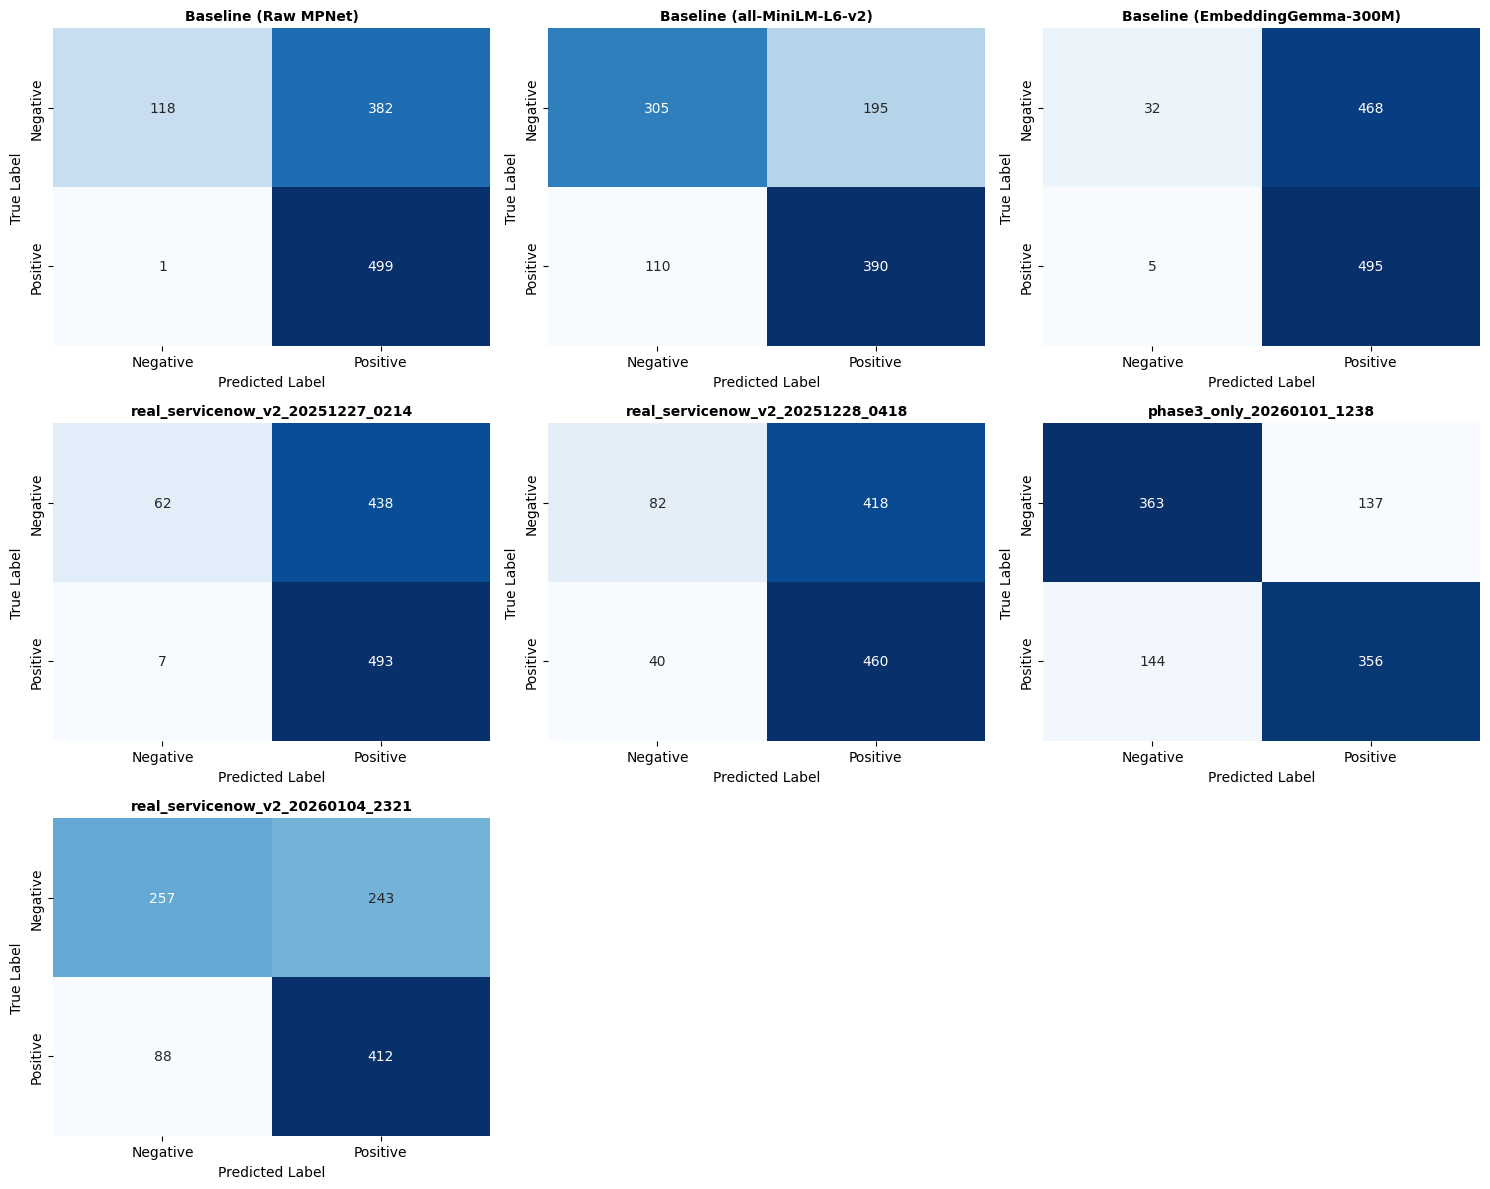


Confusion matrices for 7 models


In [13]:
import math

num_models = len(evaluator.results)
if num_models == 0:
    print('No models to visualize')
else:
    ncols = min(3, num_models)
    nrows = math.ceil(num_models / ncols)
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*5, nrows*4))
    axes = np.atleast_1d(axes).flatten()
    
    for idx, (model_name, result) in enumerate(evaluator.results.items()):
        ax = axes[idx]
        cm = np.array(result['metrics']['confusion_matrix'])
        
        sns.heatmap(cm, annot=True, fmt='d', ax=ax, cmap='Blues',
                    xticklabels=['Negative', 'Positive'],
                    yticklabels=['Negative', 'Positive'],
                    cbar=False)
        
        ax.set_title(f'{model_name}', fontweight='bold', fontsize=10)
        ax.set_ylabel('True Label')
        ax.set_xlabel('Predicted Label')
    
    # Hide unused subplots
    for idx in range(num_models, len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print(f'\nConfusion matrices for {num_models} models')


## 12. Error Analysis (NEW!)

In [14]:
if ENABLE_ERROR_ANALYSIS:
    print('='*80)
    print('ERROR ANALYSIS')
    print('='*80)
    
    for model_name, result in evaluator.results.items():
        print(f'\n{"-"*80}')
        print(f'{model_name}')
        print(f'{"-"*80}')
        
        # Analyze errors
        errors = analyze_errors(
            test_texts1,
            test_texts2,
            result['labels'],
            result['cosine_scores'],
            threshold=result['metrics']['best_threshold'],
            num_examples=NUM_ERROR_EXAMPLES
        )
        
        fp = errors['false_positives']
        fn = errors['false_negatives']
        
        print(f'\nFalse Positives: {fp["count"]} ({fp["percentage"]:.1f}%)')
        print(f'  Mean score: {fp["mean_score"]:.4f} ± {fp["std_score"]:.4f}')
        print(f'  Examples (predicted similar, actually different):')
        for i, ex in enumerate(fp['examples'][:3], 1):
            print(f'    {i}. Score={ex["score"]:.4f}')
            print(f'       Text1: {ex["text1"]}...')
            print(f'       Text2: {ex["text2"]}...')
        
        print(f'\nFalse Negatives: {fn["count"]} ({fn["percentage"]:.1f}%)')
        print(f'  Mean score: {fn["mean_score"]:.4f} ± {fn["std_score"]:.4f}')
        print(f'  Examples (predicted different, actually similar):')
        for i, ex in enumerate(fn['examples'][:3], 1):
            print(f'    {i}. Score={ex["score"]:.4f}')
            print(f'       Text1: {ex["text1"]}...')
            print(f'       Text2: {ex["text2"]}...')
else:
    print('Error analysis disabled in configuration')


ERROR ANALYSIS

--------------------------------------------------------------------------------
Baseline (Raw MPNet)
--------------------------------------------------------------------------------

False Positives: 382 (38.2%)
  Mean score: 0.3921 ± 0.0560
  Examples (predicted similar, actually different):
    1. Score=0.3224
       Text1: INC0032084 PSV CS changed printer from HP LaserJet Pro MFP M225 (10.92.194.149) to ApeosPort-V C4476...
       Text2: INC0053105 Please guide how to process intercompany asset transfer from MA to ME. User confirm to cl...
    2. Score=0.3570
       Text1: INC0060004 Dear Team

Error occurred while processing the EDI transaction. Please find the details b...
       Text2: INC0010891 Shipto code; 6000035940 doesn't sync to SFDC Create Order page. Issue as attachment
Quot...
    3. Score=0.3627
       Text1: INC0040022 PM-WO-2410000255 / REMOVE PRICING FROM WOLI Resolved...
       Text2: INC0041236 Dear Team

Error occurred while processing the EDI t

## 13. Visualizations

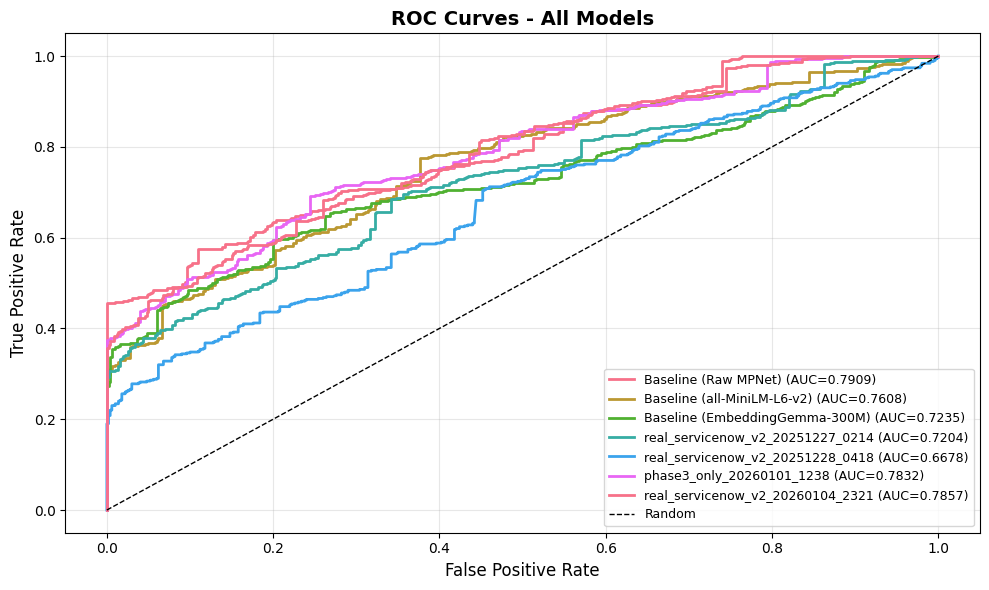

ROC curves plotted


In [15]:
# ROC Curves
fig, ax = plt.subplots(figsize=(10, 6))

for model_name, result in evaluator.results.items():
    fpr, tpr, _ = roc_curve(result['labels'], result['cosine_scores'])
    auc = result['metrics']['roc_auc']
    ax.plot(fpr, tpr, label=f"{model_name} (AUC={auc:.4f})", linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', label='Random', linewidth=1)
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves - All Models', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('ROC curves plotted')


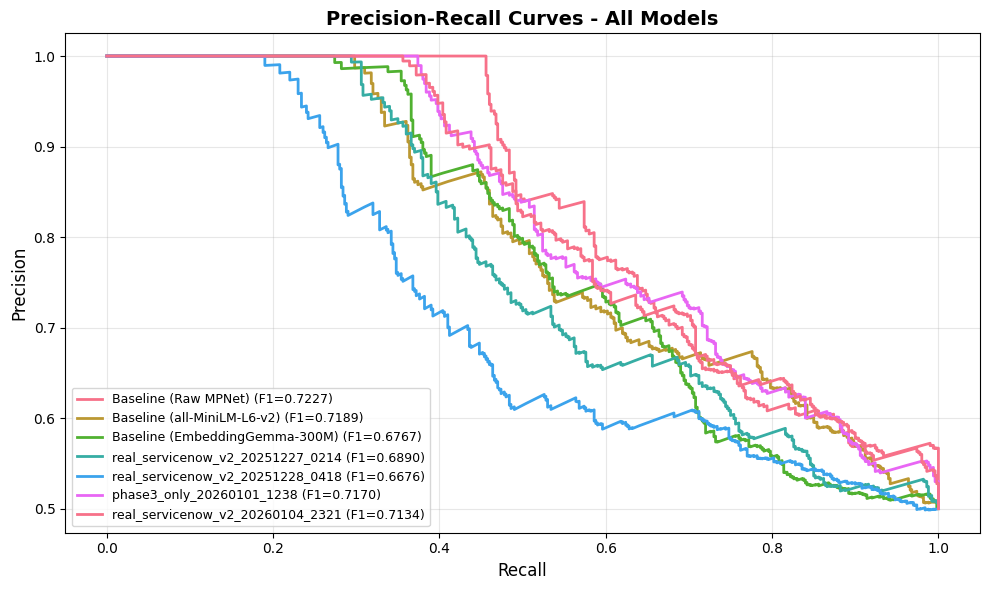

PR curves plotted


In [16]:
# Precision-Recall Curves
fig, ax = plt.subplots(figsize=(10, 6))

for model_name, result in evaluator.results.items():
    precision, recall, _ = precision_recall_curve(result['labels'], result['cosine_scores'])
    f1 = result['metrics']['f1']
    ax.plot(recall, precision, label=f"{model_name} (F1={f1:.4f})", linewidth=2)

ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title('Precision-Recall Curves - All Models', fontsize=14, fontweight='bold')
ax.legend(loc='lower left', fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('PR curves plotted')


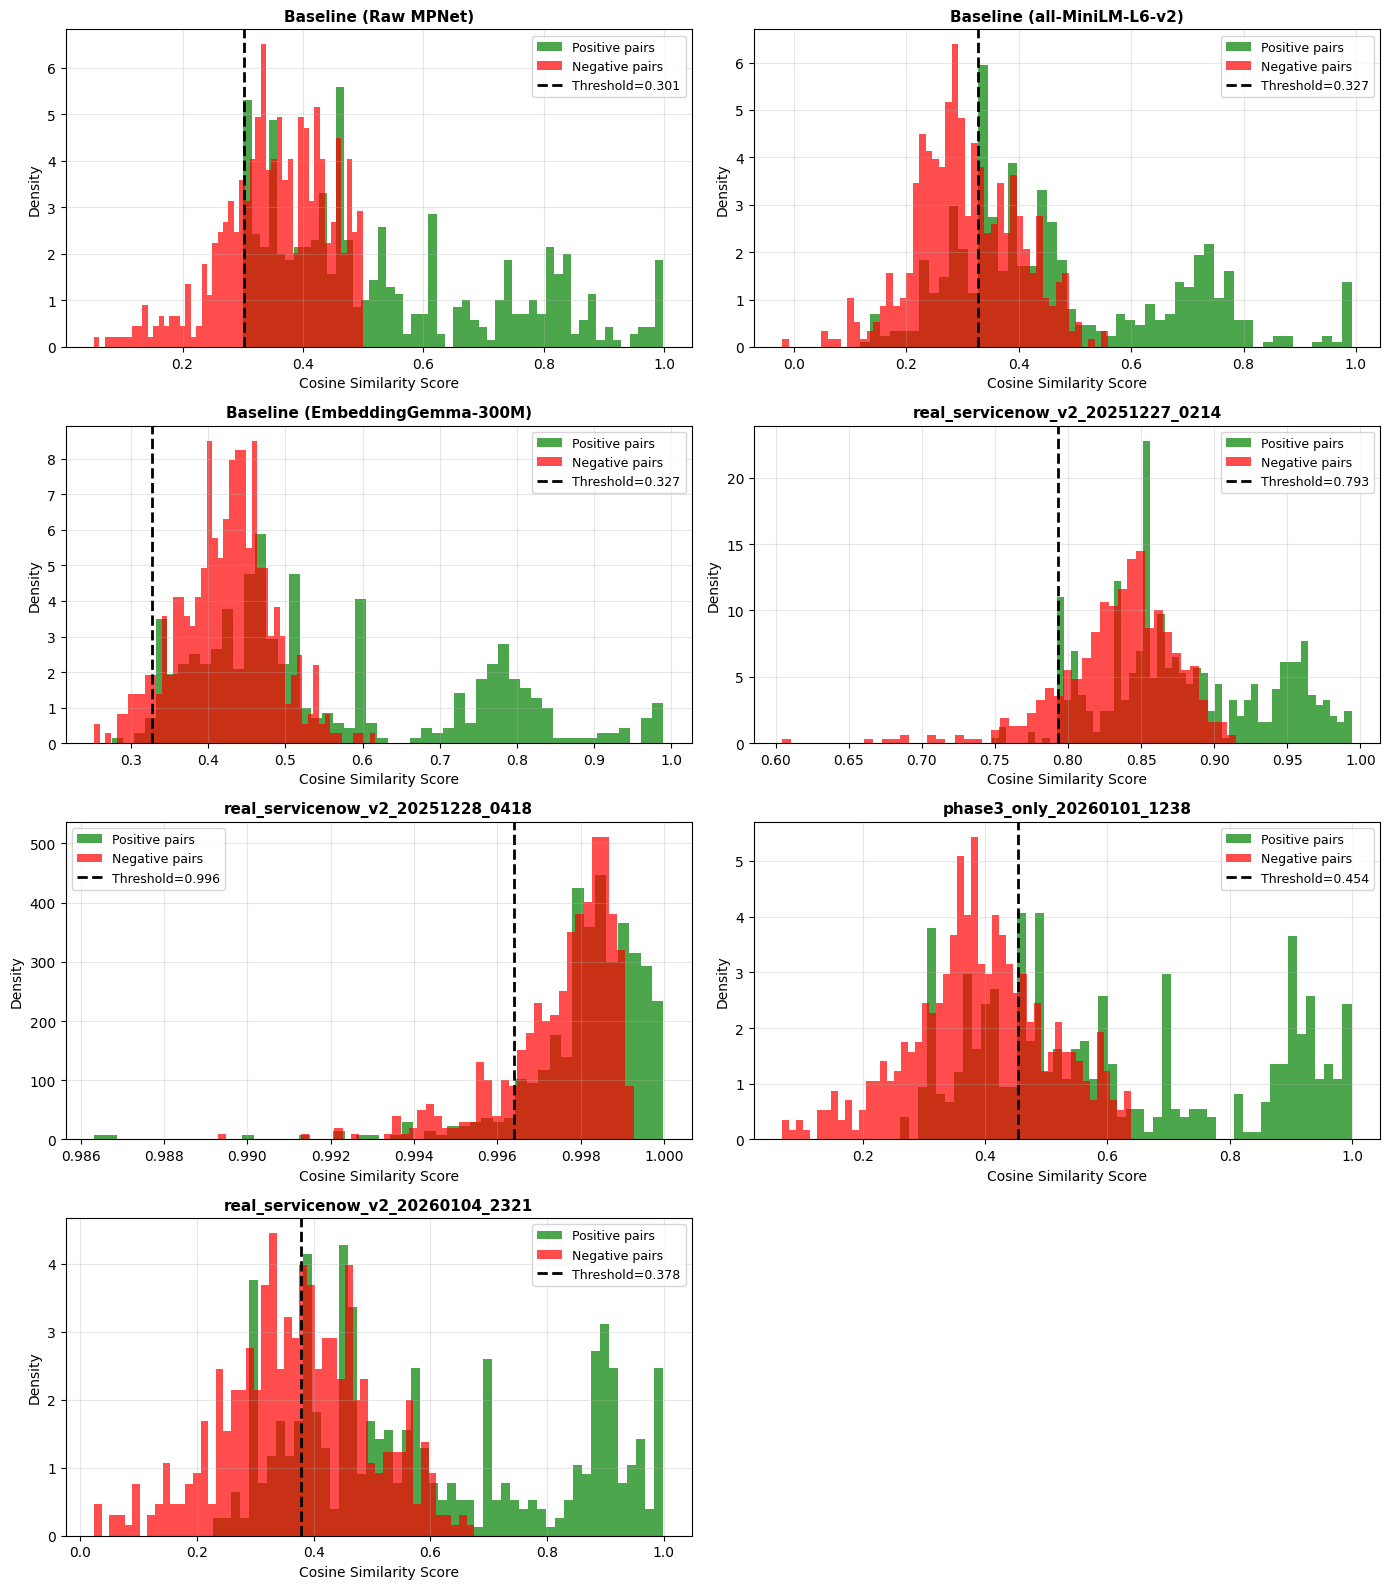

Score distributions plotted


In [17]:
# Score Distributions
num_models = len(evaluator.results)
ncols = min(2, num_models)
nrows = math.ceil(num_models / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*7, nrows*4))
axes = np.atleast_1d(axes).flatten()

for idx, (model_name, result) in enumerate(evaluator.results.items()):
    ax = axes[idx]
    
    scores = result['cosine_scores']
    labels = result['labels']
    threshold = result['metrics']['best_threshold']
    
    # Plot distributions
    ax.hist(scores[labels == 1], bins=50, alpha=0.7, label='Positive pairs',
            color='green', density=True)
    ax.hist(scores[labels == 0], bins=50, alpha=0.7, label='Negative pairs',
            color='red', density=True)
    ax.axvline(threshold, color='black', linestyle='--', linewidth=2,
               label=f'Threshold={threshold:.3f}')
    
    ax.set_xlabel('Cosine Similarity Score', fontsize=10)
    ax.set_ylabel('Density', fontsize=10)
    ax.set_title(f'{model_name}', fontsize=11, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

# Hide unused subplots
for idx in range(num_models, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

print('Score distributions plotted')


## 14. Export Results

In [18]:
# Create timestamp
timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')

# Create output directory
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save metrics CSV
metrics_csv_path = RESULTS_DIR / f'model_evaluation_{timestamp}.csv'
metrics_df.to_csv(metrics_csv_path)
print(f'Saved metrics: {metrics_csv_path}')

# Save detailed results JSON
results_dict = {}
for model_name, result in evaluator.results.items():
    results_dict[model_name] = result['metrics']  # Don't save embeddings (too large)

results_json_path = RESULTS_DIR / f'evaluation_results_{timestamp}.json'
with open(results_json_path, 'w', encoding='utf-8') as f:
    json.dump(results_dict, f, indent=2, default=str)
print(f'Saved results: {results_json_path}')

# Save environment metadata
metadata = get_environment_metadata()
metadata['evaluation_config'] = {
    'test_pairs_file': str(TEST_PAIRS_FILE),
    'num_test_pairs': len(test_labels),
    'baseline_model': BASELINE_MODEL,
    'num_models_evaluated': len(evaluator.results),
    'random_seed': RANDOM_SEED,
}

metadata_path = RESULTS_DIR / f'evaluation_metadata_{timestamp}.json'
with open(metadata_path, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2, default=str)
print(f'Saved metadata: {metadata_path}')

print(f'\nAll results exported to: {RESULTS_DIR}')


Saved metrics: c:\Users\donov\Documents\itsm project\nexustism\nexustism\models\results\model_evaluation_20260105_001029.csv
Saved results: c:\Users\donov\Documents\itsm project\nexustism\nexustism\models\results\evaluation_results_20260105_001029.json
Saved metadata: c:\Users\donov\Documents\itsm project\nexustism\nexustism\models\results\evaluation_metadata_20260105_001029.json

All results exported to: c:\Users\donov\Documents\itsm project\nexustism\nexustism\models\results


## 15. Summary

In [19]:
print('='*80)
print('EVALUATION SUMMARY')
print('='*80)

# Best model overall
best_model = metrics_df['spearman'].idxmax()
best_spearman = metrics_df['spearman'].max()

print(f'\nBest Model (by Spearman): {best_model}')
print(f'   Spearman: {best_spearman:.4f}')

# Compare to baseline
baseline_spearman = evaluator.results['Baseline (Raw MPNet)']['metrics']['spearman']
improvement = best_spearman - baseline_spearman
improvement_pct = (improvement / baseline_spearman * 100) if baseline_spearman else 0

print(f'\nComparison to Baseline:')
print(f'   Baseline (MPNet): {baseline_spearman:.4f}')
print(f'   Best model:       {best_spearman:.4f}')
print(f'   Improvement:      {improvement:+.4f} ({improvement_pct:+.1f}%)')

if improvement > 0.01:
    print('   SIGNIFICANT improvement over baseline!')
elif improvement > -0.01:
    print('   Similar performance to baseline')
else:
    print('   Below baseline performance')

# Top 3 models
print(f'\nTop 3 Models (by Spearman):')
for i, (model_name, row) in enumerate(metrics_df.head(3).iterrows(), 1):
    print(f'   {i}. {model_name:40s} (Spearman: {row["spearman"]:.4f})')

# Recommendations
print(f'\nRecommendations:')
if best_spearman >= 0.80:
    print('   Model ready for production (Spearman >= 0.80)')
elif best_spearman >= 0.70:
    print('   Model decent but could be improved (0.70 <= Spearman < 0.80)')
else:
    print('   Model needs significant improvement (Spearman < 0.70)')
    print('   Consider:')
    print('     - More training data')
    print('     - Different model architecture')
    print('     - Better hard negative mining')
    print('     - Curriculum learning approach')

print(f'\n{"="*80}')
print('EVALUATION COMPLETE')
print(f'{"="*80}')


EVALUATION SUMMARY

Best Model (by Spearman): Baseline (Raw MPNet)
   Spearman: 0.5038

Comparison to Baseline:
   Baseline (MPNet): 0.5038
   Best model:       0.5038
   Improvement:      +0.0000 (+0.0%)
   Similar performance to baseline

Top 3 Models (by Spearman):
   1. Baseline (Raw MPNet)                     (Spearman: 0.5038)
   2. real_servicenow_v2_20260104_2321         (Spearman: 0.4949)
   3. phase3_only_20260101_1238                (Spearman: 0.4905)

Recommendations:
   Model needs significant improvement (Spearman < 0.70)
   Consider:
     - More training data
     - Different model architecture
     - Better hard negative mining
     - Curriculum learning approach

EVALUATION COMPLETE


In [ ]:
if CLUSTERING_ENABLED and clustering_results:
    print('='*80)
    print('CLUSTERING SUMMARY')
    print('='*80)
    
    # Compare algorithms by silhouette score
    silhouette_scores = {}
    for algo_name, result in clustering_results.items():
        if 'silhouette' in result:
            silhouette_scores[algo_name] = result['silhouette']
    
    if silhouette_scores:
        print('\nAlgorithm Comparison (by Silhouette Score):')
        for algo_name, score in sorted(silhouette_scores.items(), key=lambda x: -x[1]):
            print(f'  {algo_name:20s}: {score:.4f}')
        
        best_algo = max(silhouette_scores.items(), key=lambda x: x[1])
        print(f'\nBest Algorithm: {best_algo[0]} (Silhouette={best_algo[1]:.4f})')
    
    # Summary table
    print('\n' + '='*80)
    print('Algorithm Details:')
    print('='*80)
    
    for algo_name, result in clustering_results.items():
        print(f'\n{algo_name.upper()}:')
        for key, value in result.items():
            if key != 'labels':  # Skip the labels array
                print(f'  {key:20s}: {value}')
    
    # Recommendations
    print(f'\n{"="*80}')
    print('RECOMMENDATIONS')
    print(f'{"="*80}')
    
    print('\nUse Cases:')
    print('  K-Means:        Fast, when you know the number of clusters')
    print('  DBSCAN:         Find arbitrary shapes, detect outliers')
    print('  HDBSCAN:        Best for varying density, hierarchical structure')
    print('  Agglomerative:  Hierarchical relationships, dendrograms')
    
    print('\nNext Steps:')
    print('  1. Adjust algorithm parameters in Section 1 CONFIG')
    print('  2. Try different cluster counts (KMEANS_N_CLUSTERS, AGGLOMERATIVE_N_CLUSTERS)')
    print('  3. Tune density parameters (DBSCAN_EPS, HDBSCAN_MIN_CLUSTER_SIZE)')
    print('  4. Export cluster labels for production use')
    print('  5. Analyze cluster characteristics (incident types, categories, etc.)')
    
    print(f'\n{"="*80}')

### 16f. Clustering Summary & Recommendations

In [ ]:
if CLUSTERING_ENABLED and clustering_results:
    from sklearn.manifold import TSNE
    
    print(f'\n{"="*80}')
    print('CLUSTERING VISUALIZATION')
    print(f'{"="*80}')
    
    # Reduce to 2D using t-SNE for visualization
    print('\nReducing embeddings to 2D with t-SNE...')
    tsne = TSNE(n_components=2, random_state=RANDOM_SEED, perplexity=30, n_iter=1000)
    embeddings_2d = tsne.fit_transform(cluster_embeddings)
    
    # Plot each clustering algorithm
    num_algorithms = len(clustering_results)
    ncols = min(2, num_algorithms)
    nrows = math.ceil(num_algorithms / ncols)
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*8, nrows*6))
    axes = np.atleast_1d(axes).flatten()
    
    for idx, (algo_name, result) in enumerate(clustering_results.items()):
        ax = axes[idx]
        labels = result['labels']
        
        # Plot points
        scatter = ax.scatter(
            embeddings_2d[:, 0],
            embeddings_2d[:, 1],
            c=labels,
            cmap='tab20',
            alpha=0.6,
            s=20,
            edgecolors='k',
            linewidths=0.5
        )
        
        # Mark outliers (label -1) in black
        outliers = labels == -1
        if outliers.any():
            ax.scatter(
                embeddings_2d[outliers, 0],
                embeddings_2d[outliers, 1],
                c='black',
                marker='x',
                s=50,
                alpha=0.8,
                label='Outliers'
            )
        
        # Title with metrics
        title = f'{algo_name.upper()}\n'
        if 'n_clusters' in result:
            title += f"Clusters: {result['n_clusters']}"
        if 'n_outliers' in result and result['n_outliers'] > 0:
            title += f", Outliers: {result['n_outliers']}"
        if 'silhouette' in result:
            title += f"\nSilhouette: {result['silhouette']:.3f}"
        
        ax.set_title(title, fontweight='bold', fontsize=11)
        ax.set_xlabel('t-SNE Dimension 1', fontsize=10)
        ax.set_ylabel('t-SNE Dimension 2', fontsize=10)
        ax.grid(True, alpha=0.3)
        
        if outliers.any():
            ax.legend(fontsize=9)
    
    # Hide unused subplots
    for idx in range(num_algorithms, len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print(f'\nVisualized {num_algorithms} clustering algorithms')

### 16e. Clustering Visualization

In [ ]:
if CLUSTERING_ENABLED and 'agglomerative' in CLUSTERING_ALGORITHMS:
    from sklearn.cluster import AgglomerativeClustering
    
    print(f'\n{"-"*80}')
    print('AGGLOMERATIVE CLUSTERING')
    print(f'{"-"*80}')
    
    # Fit Agglomerative
    agg = AgglomerativeClustering(
        n_clusters=AGGLOMERATIVE_N_CLUSTERS,
        linkage=AGGLOMERATIVE_LINKAGE
    )
    agg_labels = agg.fit_predict(cluster_embeddings)
    
    # Compute quality metrics
    silhouette = silhouette_score(cluster_embeddings, agg_labels)
    calinski = calinski_harabasz_score(cluster_embeddings, agg_labels)
    davies_bouldin = davies_bouldin_score(cluster_embeddings, agg_labels)
    
    clustering_results['agglomerative'] = {
        'labels': agg_labels,
        'n_clusters': AGGLOMERATIVE_N_CLUSTERS,
        'linkage': AGGLOMERATIVE_LINKAGE,
        'silhouette': silhouette,
        'calinski_harabasz': calinski,
        'davies_bouldin': davies_bouldin,
    }
    
    print(f'\nClusters: {AGGLOMERATIVE_N_CLUSTERS}, Linkage: {AGGLOMERATIVE_LINKAGE}')
    print(f'Silhouette Score:      {silhouette:.4f} (higher is better)')
    print(f'Calinski-Harabasz:     {calinski:.2f} (higher is better)')
    print(f'Davies-Bouldin:        {davies_bouldin:.4f} (lower is better)')
    
    # Cluster size distribution
    unique, counts = np.unique(agg_labels, return_counts=True)
    print(f'\nCluster sizes:')
    for cluster_id, count in zip(unique, counts):
        pct = count / len(agg_labels) * 100
        print(f'  Cluster {cluster_id:2d}: {count:4d} incidents ({pct:5.1f}%)')

### 16d. Agglomerative Clustering

In [ ]:
if CLUSTERING_ENABLED and 'hdbscan' in CLUSTERING_ALGORITHMS:
    try:
        import hdbscan
        
        print(f'\n{"-"*80}')
        print('HDBSCAN CLUSTERING')
        print(f'{"-"*80}')
        
        # Fit HDBSCAN
        clusterer = hdbscan.HDBSCAN(
            min_cluster_size=HDBSCAN_MIN_CLUSTER_SIZE,
            min_samples=HDBSCAN_MIN_SAMPLES,
            metric='cosine',
            cluster_selection_method='eom'
        )
        hdbscan_labels = clusterer.fit_predict(cluster_embeddings)
        
        # Count clusters and outliers
        n_clusters = len(set(hdbscan_labels)) - (1 if -1 in hdbscan_labels else 0)
        n_outliers = list(hdbscan_labels).count(-1)
        
        clustering_results['hdbscan'] = {
            'labels': hdbscan_labels,
            'n_clusters': n_clusters,
            'n_outliers': n_outliers,
            'min_cluster_size': HDBSCAN_MIN_CLUSTER_SIZE,
            'min_samples': HDBSCAN_MIN_SAMPLES,
        }
        
        print(f'\nMin cluster size: {HDBSCAN_MIN_CLUSTER_SIZE}, Min samples: {HDBSCAN_MIN_SAMPLES}')
        print(f'Clusters found: {n_clusters}')
        print(f'Outliers: {n_outliers} ({n_outliers/len(hdbscan_labels)*100:.1f}%)')
        
        # Cluster stability scores
        if hasattr(clusterer, 'cluster_persistence_'):
            print(f'\nCluster persistence (stability):')
            for cluster_id in range(n_clusters):
                if cluster_id < len(clusterer.cluster_persistence_):
                    persistence = clusterer.cluster_persistence_[cluster_id]
                    print(f'  Cluster {cluster_id:2d}: {persistence:.4f}')
        
        # Compute silhouette (if we have clusters)
        if n_clusters > 1:
            non_outlier_mask = hdbscan_labels != -1
            if non_outlier_mask.sum() > 1:
                silhouette = silhouette_score(
                    cluster_embeddings[non_outlier_mask],
                    hdbscan_labels[non_outlier_mask]
                )
                clustering_results['hdbscan']['silhouette'] = silhouette
                print(f'Silhouette Score:      {silhouette:.4f} (excluding outliers)')
        
        # Cluster size distribution
        if n_clusters > 0:
            unique, counts = np.unique(hdbscan_labels[hdbscan_labels != -1], return_counts=True)
            print(f'\nCluster sizes (excluding {n_outliers} outliers):')
            for cluster_id, count in sorted(zip(unique, counts), key=lambda x: -x[1])[:10]:
                pct = count / len(hdbscan_labels) * 100
                print(f'  Cluster {cluster_id:3d}: {count:4d} incidents ({pct:5.1f}%)')
        
    except ImportError:
        print('\nHDBSCAN not installed. Install with: conda install -c conda-forge hdbscan')
        print('Skipping HDBSCAN clustering...')

### 16c. HDBSCAN Clustering

In [ ]:
if CLUSTERING_ENABLED and 'dbscan' in CLUSTERING_ALGORITHMS:
    from sklearn.cluster import DBSCAN
    
    print(f'\n{"-"*80}')
    print('DBSCAN CLUSTERING')
    print(f'{"-"*80}')
    
    # Fit DBSCAN (using cosine distance)
    dbscan = DBSCAN(eps=DBSCAN_EPS, min_samples=DBSCAN_MIN_SAMPLES, metric='cosine')
    dbscan_labels = dbscan.fit_predict(cluster_embeddings)
    
    # Count clusters and outliers
    n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
    n_outliers = list(dbscan_labels).count(-1)
    
    clustering_results['dbscan'] = {
        'labels': dbscan_labels,
        'n_clusters': n_clusters,
        'n_outliers': n_outliers,
        'eps': DBSCAN_EPS,
        'min_samples': DBSCAN_MIN_SAMPLES,
    }
    
    print(f'\nEps: {DBSCAN_EPS}, Min samples: {DBSCAN_MIN_SAMPLES}')
    print(f'Clusters found: {n_clusters}')
    print(f'Outliers: {n_outliers} ({n_outliers/len(dbscan_labels)*100:.1f}%)')
    
    # Compute silhouette (if we have clusters)
    if n_clusters > 1:
        # Exclude outliers for silhouette calculation
        non_outlier_mask = dbscan_labels != -1
        if non_outlier_mask.sum() > 1:
            silhouette = silhouette_score(
                cluster_embeddings[non_outlier_mask], 
                dbscan_labels[non_outlier_mask]
            )
            clustering_results['dbscan']['silhouette'] = silhouette
            print(f'Silhouette Score:      {silhouette:.4f} (excluding outliers)')
    
    # Cluster size distribution
    if n_clusters > 0:
        unique, counts = np.unique(dbscan_labels[dbscan_labels != -1], return_counts=True)
        print(f'\nCluster sizes (excluding {n_outliers} outliers):')
        for cluster_id, count in sorted(zip(unique, counts), key=lambda x: -x[1])[:10]:
            pct = count / len(dbscan_labels) * 100
            print(f'  Cluster {cluster_id:3d}: {count:4d} incidents ({pct:5.1f}%)')
    else:
        print('\nNo clusters found - try adjusting eps or min_samples')

### 16b. DBSCAN Clustering

In [ ]:
if CLUSTERING_ENABLED and 'kmeans' in CLUSTERING_ALGORITHMS:
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
    
    print(f'\n{"-"*80}')
    print('K-MEANS CLUSTERING')
    print(f'{"-"*80}')
    
    # Fit K-Means
    kmeans = KMeans(n_clusters=KMEANS_N_CLUSTERS, random_state=RANDOM_SEED, n_init=10)
    kmeans_labels = kmeans.fit_predict(cluster_embeddings)
    
    # Compute quality metrics
    silhouette = silhouette_score(cluster_embeddings, kmeans_labels)
    calinski = calinski_harabasz_score(cluster_embeddings, kmeans_labels)
    davies_bouldin = davies_bouldin_score(cluster_embeddings, kmeans_labels)
    
    clustering_results['kmeans'] = {
        'labels': kmeans_labels,
        'n_clusters': KMEANS_N_CLUSTERS,
        'silhouette': silhouette,
        'calinski_harabasz': calinski,
        'davies_bouldin': davies_bouldin,
    }
    
    print(f'\nClusters: {KMEANS_N_CLUSTERS}')
    print(f'Silhouette Score:      {silhouette:.4f} (higher is better, range [-1, 1])')
    print(f'Calinski-Harabasz:     {calinski:.2f} (higher is better)')
    print(f'Davies-Bouldin:        {davies_bouldin:.4f} (lower is better)')
    
    # Cluster size distribution
    unique, counts = np.unique(kmeans_labels, return_counts=True)
    print(f'\nCluster sizes:')
    for cluster_id, count in zip(unique, counts):
        pct = count / len(kmeans_labels) * 100
        print(f'  Cluster {cluster_id:2d}: {count:4d} incidents ({pct:5.1f}%)')
    
    # Sample incidents from each cluster
    print(f'\nSample incidents per cluster (first 2 tokens):')
    for cluster_id in unique[:5]:  # Show first 5 clusters
        cluster_indices = np.where(kmeans_labels == cluster_id)[0]
        sample_idx = cluster_indices[0]
        sample_text = cluster_texts[sample_idx][:80]
        print(f'  Cluster {cluster_id:2d}: {sample_text}...')

### 16a. K-Means Clustering

In [ ]:
if not CLUSTERING_ENABLED:
    print('Clustering disabled in configuration')
else:
    print('='*80)
    print('CLUSTERING ANALYSIS')
    print('='*80)
    
    # Check if we have any models evaluated
    if not evaluator.results:
        print('\nNo models evaluated yet. Run evaluation cells first.')
    else:
        # Use the best model for clustering demo
        best_model_name = metrics_df['spearman'].idxmax()
        print(f'\nUsing best model for clustering: {best_model_name}')
        
        # Get embeddings from test set (use both texts)
        best_result = evaluator.results[best_model_name]
        all_embeddings = np.vstack([best_result['embeddings1'], best_result['embeddings2']])
        all_texts = test_texts1 + test_texts2
        all_labels = np.concatenate([test_labels, test_labels])  # Duplicate labels for both texts
        
        # Sample if too large
        if len(all_embeddings) > CLUSTERING_SAMPLE_SIZE:
            print(f'\nSampling {CLUSTERING_SAMPLE_SIZE} incidents from {len(all_embeddings)} total')
            sample_indices = np.random.choice(len(all_embeddings), CLUSTERING_SAMPLE_SIZE, replace=False)
            cluster_embeddings = all_embeddings[sample_indices]
            cluster_texts = [all_texts[i] for i in sample_indices]
        else:
            cluster_embeddings = all_embeddings
            cluster_texts = all_texts
        
        print(f'Clustering {len(cluster_embeddings)} incidents with {cluster_embeddings.shape[1]}-dim embeddings')
        
        # Store clustering results
        clustering_results = {}

## 16. Clustering Analysis (NEW!)

**Purpose:** Demonstrate how the fine-tuned model can be used for incident clustering.

**Algorithms Tested:**
- **K-Means**: Fast, partition-based clustering
- **DBSCAN**: Density-based, finds arbitrary shapes, detects outliers
- **HDBSCAN**: Hierarchical DBSCAN, better for varying densities
- **Agglomerative**: Hierarchical clustering with linkage criteria

**Why it works:**
- V4 Cosine model generates semantically meaningful 768-dim embeddings
- Curriculum learning enhanced semantic grouping
- Cosine similarity aligns with clustering distance metrics